# <center>Water Potability Prediction 💧</center>

Name: NAMBIRAJAN R S<br>Roll No: 215229125

## Importing Essential Libraries, Metrics, Tools and Models

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier

## Loading the Data

In [2]:
df = pd.read_csv("water_potability.csv")

## Exploratory Data Analysis

***Taking a look at the first 5 rows of the dataset.***

In [3]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


***Checking the shape—i.e. size—of the data.***

In [4]:
df.shape

(3276, 10)

***Learning the dtypes of columns' and how many non-null values there are in those columns.***

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


***Getting the statistical summary of dataset.***

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


## Handling Missing Values and Duplicates

In [7]:
df.isna().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

***As we can see, there are missing values in columns "ph", "Sulfate" and "Trihalomethanes".***

In [8]:
df['ph'] = df['ph'].fillna(df.groupby(['Potability'])['ph'].transform('mean'))
df['Sulfate'] = df['Sulfate'].fillna(df.groupby(['Potability'])['Sulfate'].transform('mean'))
df['Trihalomethanes'] = df['Trihalomethanes'].fillna(df.groupby(['Potability'])['Trihalomethanes'].transform('mean'))

***It seems that there is no duplicate in the dataset.***

In [9]:
df.duplicated().sum()

0

## Data Visualization

***Visualizing the Correlation between the ten numerical real-valued variables using pairplot visualization.***

* Blue ---> **Non Potable**
* Orange ---> **Potable**

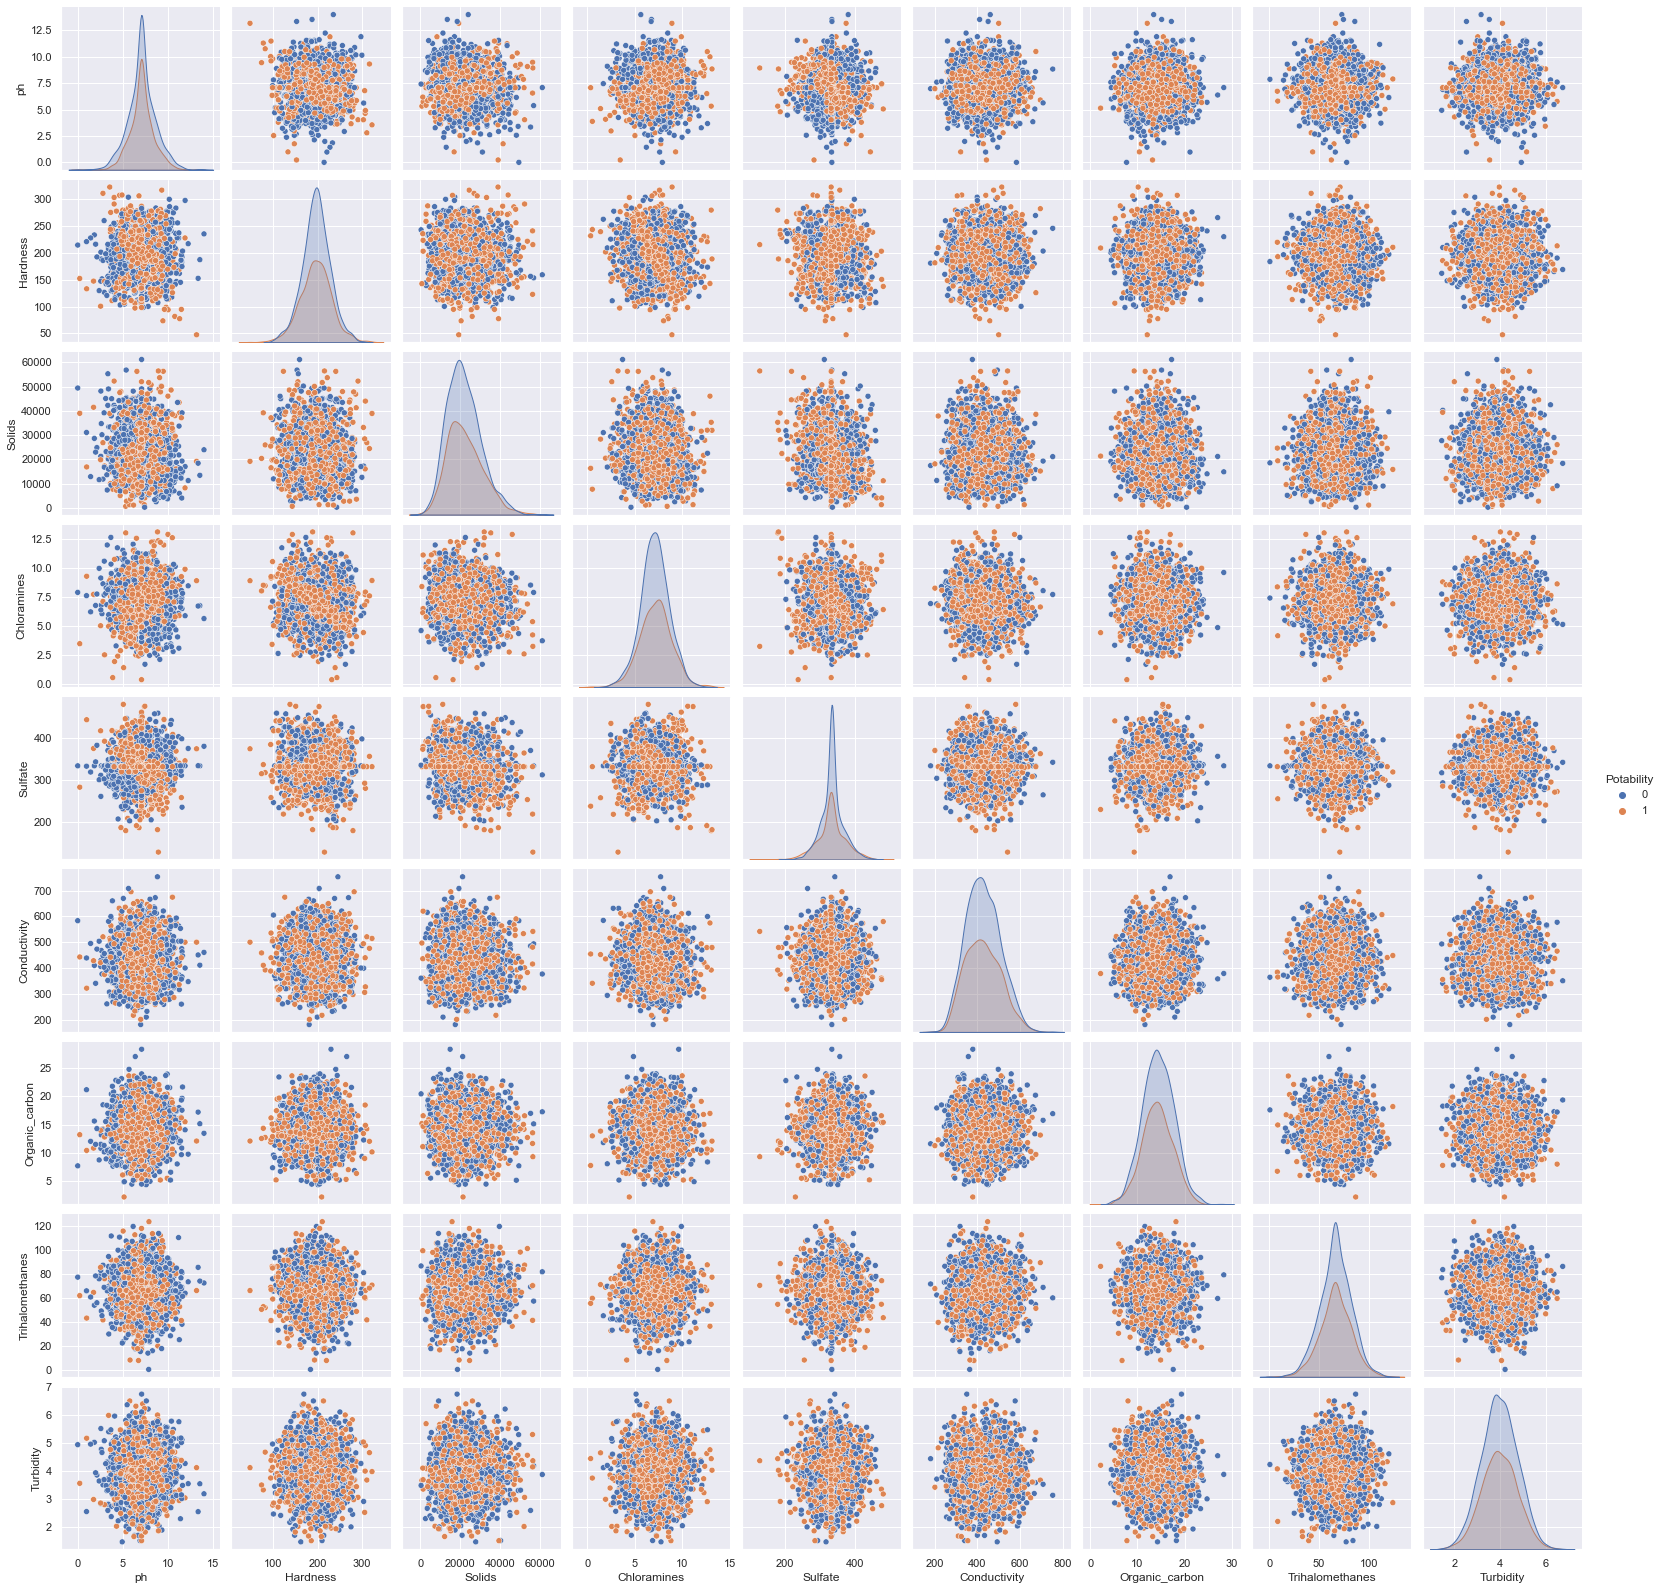

In [10]:
sns.set()

sns.pairplot(df, hue="Potability")

In [11]:
labels = ['Not Potable','Potable']
values = [df[df["Potability"]==0].shape[0], df[df["Potability"]==1].shape[0]]

fig = go.Figure(data=[go.Pie(labels=labels, values=values, hole=0.5, title="Potability")])
fig.show()

***Visualizing the linear correlations between variables using Heatmap Visualization.***

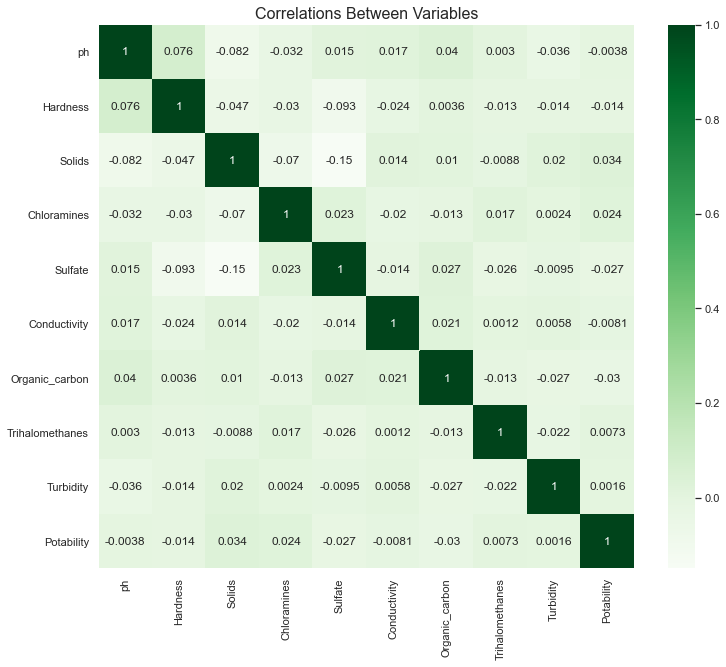

In [12]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap="Greens")
plt.title("Correlations Between Variables", size=16)
plt.show()

## Data Preprocessing

<h3>X, y Split</h3>

In [13]:
X = df.drop("Potability", axis=1)
y = df["Potability"]

<h3>Data Standardization</h3>

In [14]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

<h3>Train-Test Split</h3>

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Machine Learning Models

In [16]:
models = pd.DataFrame(columns=["Model", "Accuracy Score"])

In [17]:
model_list = [("Logistic Regression", LogisticRegression(random_state=42)), 
              ("Random Forest", RandomForestClassifier(random_state=42)),
              ("Support Vector Machines", SVC(random_state=42)),
              ("Gaussian Naive Bayes", GaussianNB()),
              ("Bernoulli Naive Bayes", BernoulliNB()),
              ("KNearestNeighbor", KNeighborsClassifier(n_neighbors=2)),
              ("Decision Tree", DecisionTreeClassifier(random_state=42)),
              ("Bagging Classifier", BaggingClassifier(base_estimator=RandomForestClassifier(), random_state=42))]

In [18]:
for name, clf in model_list:
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)
    score = accuracy_score(y_test, predictions)
    
    new_row = {"Model": name, "Accuracy Score": score}
    models = models.append(new_row, ignore_index=True)

In [19]:
models

,Model,Accuracy Score
0,Logistic Regression,0.628049
1,Random Forest,0.824695
2,Support Vector Machines,0.699695
3,Gaussian Naive Bayes,0.631098
4,Bernoulli Naive Bayes,0.632622
5,KNearestNeighbor,0.663110
6,Decision Tree,0.746951
7,Bagging Classifier,0.806402


***It can be seen that the one which is yielding the most accurate result without Hyperparameter Tuning is Random Forest.***

In [20]:
models.sort_values(by="Accuracy Score", ascending=False)

,Model,Accuracy Score
1,Random Forest,0.824695
7,Bagging Classifier,0.806402
6,Decision Tree,0.746951
2,Support Vector Machines,0.699695
5,KNearestNeighbor,0.663110
4,Bernoulli Naive Bayes,0.632622
3,Gaussian Naive Bayes,0.631098
0,Logistic Regression,0.628049


***Defining a ROC AUC Curve visualization function for the convenience of evaluation.***

In [21]:
def visualize_roc_auc_curve(model, model_name):
    pred_prob = model.predict_proba(X_test)
    fpr, tpr, thresh = roc_curve(y_test, pred_prob[:, 1], pos_label=1)
    
    score = roc_auc_score(y_test, pred_prob[:, 1])
    
    plt.figure(figsize=(10,8))
    plt.plot(fpr, tpr, linestyle="--", color="orange", label="ROC AUC Score: (%0.5f)" % score)
    plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    
    plt.title(f"{model_name} ROC Curve", size=15)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right", prop={"size": 15})
    plt.show()

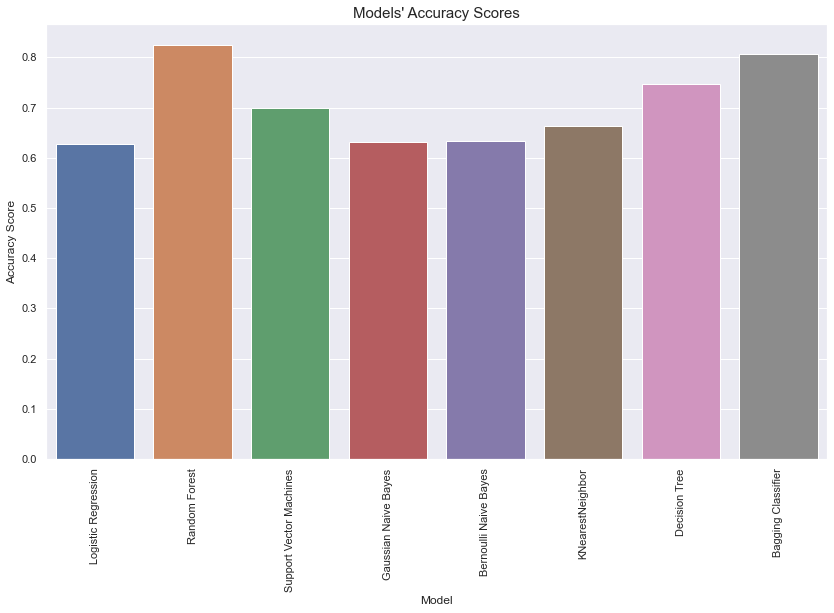

In [22]:
plt.figure(figsize=(14, 8))
sns.barplot(x=models["Model"], y=models["Accuracy Score"])
plt.title("Models' Accuracy Scores", size=15)
plt.xticks(rotation=90)
plt.show()

<h3>Confusion Matrix and ROC Curve of Random Forest</h3>

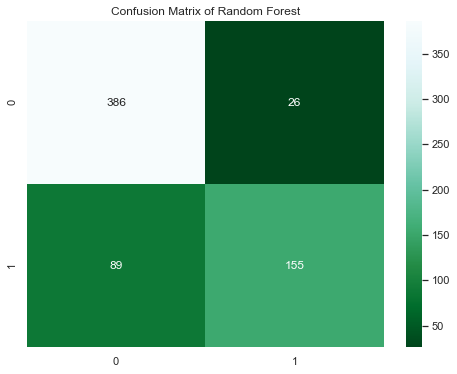

In [23]:
rfc = RandomForestClassifier(random_state=42)
rfc.fit(X_train, y_train)
predictions = rfc.predict(X_test)

plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, cmap="BuGn_r", fmt="d")
plt.title("Confusion Matrix of Random Forest")
plt.show()

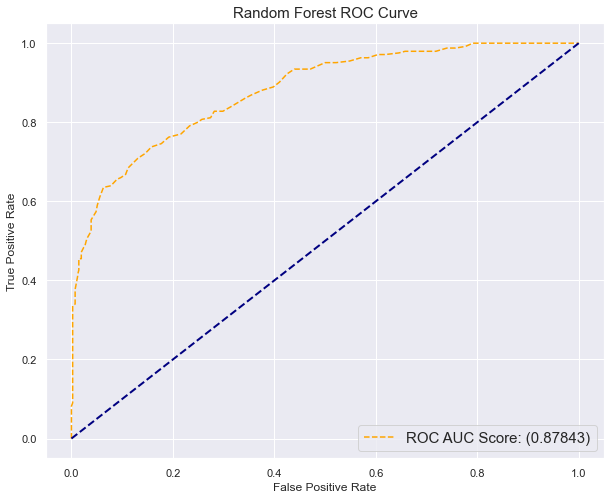

In [24]:
visualize_roc_auc_curve(rfc, "Random Forest")

### Confusion Matrix and ROC Curve of Bagging Classifier

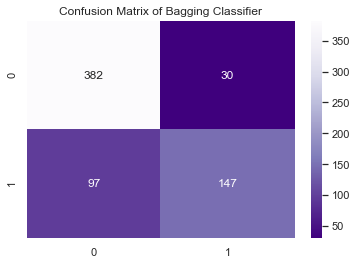

In [25]:
bc = BaggingClassifier(base_estimator=RandomForestClassifier(), random_state=42)
bc.fit(X_train, y_train)
predictions = bc.predict(X_test)

sns.heatmap(confusion_matrix(y_test, predictions), annot=True, cmap="Purples_r", fmt="d")
plt.title("Confusion Matrix of Bagging Classifier")
plt.show()

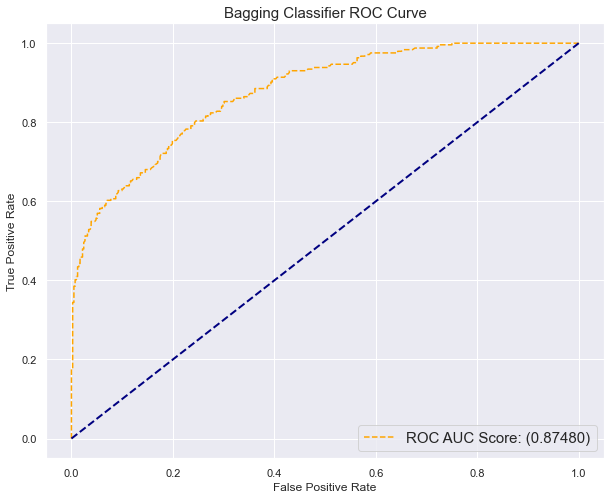

In [26]:
visualize_roc_auc_curve(bc, "Bagging Classifier")

### Confusion Matrix and ROC Curve of Decision Tree

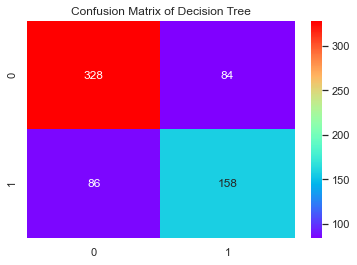

In [27]:
decT = DecisionTreeClassifier()
decT.fit(X_train, y_train)
predictions = decT.predict(X_test)

sns.heatmap(confusion_matrix(y_test, predictions), annot=True, cmap="rainbow", fmt="d")
plt.title("Confusion Matrix of Decision Tree")
plt.show()

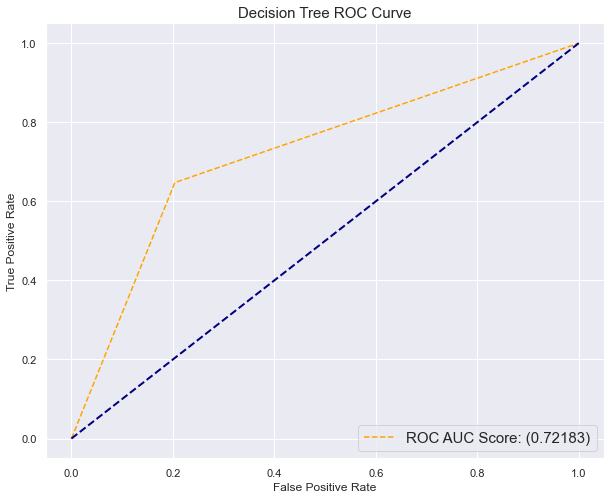

In [28]:
visualize_roc_auc_curve(decT, "Decision Tree")

## Hyperparameter Tuning

In [29]:
tuned_models = pd.DataFrame(columns=["Model", "Accuracy Score"])

<h3>Tuning the Random Forest</h3>

In [30]:
param_grid_rfc = {"min_samples_split": [2, 3, 10],
                  "min_samples_leaf": [1, 3, 10],
                  "n_estimators" :[100, 200, 500],
                  "random_state": [42]}

grid_rfc = GridSearchCV(RandomForestClassifier(), param_grid_rfc, scoring="accuracy", cv=5, verbose=0, n_jobs=-1)

grid_rfc.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'min_samples_leaf': [1, 3, 10],
                         'min_samples_split': [2, 3, 10],
                         'n_estimators': [100, 200, 500],
                         'random_state': [42]},
             scoring='accuracy')

In [31]:
rfc_params = grid_rfc.best_params_
rfc = RandomForestClassifier(**rfc_params)
rfc.fit(X_train, y_train)
predictions = rfc.predict(X_test)
score = accuracy_score(y_test, predictions)
print("Accuracy Score:", score)

new_row = {"Model": "Random Forest", "Accuracy Score": score}
tuned_models = tuned_models.append(new_row, ignore_index=True)

Accuracy Score: 0.7926829268292683


<h3>Tuning the Decision Tree</h3>

In [32]:
param_grid_dt = {'criterion':['gini','entropy'],
                  'max_depth': np.arange(3, 50)}

grid_dt = GridSearchCV(DecisionTreeClassifier(), param_grid_dt, scoring="accuracy", cv=5, verbose=0, n_jobs=-1)

grid_dt.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
       20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36,
       37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49])},
             scoring='accuracy')

In [33]:
dt_params = grid_dt.best_params_
dt = DecisionTreeClassifier(**dt_params)
dt.fit(X_train, y_train)
predictions = dt.predict(X_test)
score = accuracy_score(y_test, predictions)
print("Accuracy Score:", score)

new_row = {"Model": "Decision Tree Classifier", "Accuracy Score": score}
tuned_models = tuned_models.append(new_row, ignore_index=True)

Accuracy Score: 0.7652439024390244


## Model Comparison After Hyperparameter Tuning

***After all the Hyperparameter Tuning endeavour, there is a little bit improvement (0.016768) in the Decision Tree's result and decrease in Random Forest's accuracy scores.***

In [34]:
tuned_models.sort_values(by="Accuracy Score", ascending=False)

,Model,Accuracy Score
0,Random Forest,0.792683
1,Decision Tree Classifier,0.765244


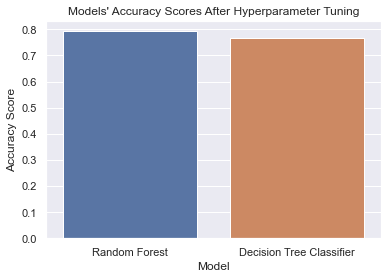

In [35]:
sns.barplot(x=tuned_models["Model"], y=tuned_models["Accuracy Score"])
plt.title("Models' Accuracy Scores After Hyperparameter Tuning")
plt.show()

## Conclusion

**It can be observed that the model which yields the most accurate result is non-tuned Random Forest Classifier with an accuracy score of 0.824695. Decision tree is slightly higher accuracy after tuned.**